In [9]:
CXR = 'utils/mappings/mimic-cxr-2.0.0-metadata.csv.gz'
ECG = 'utils/mappings/ecg_record_list.csv.gz'
ECHO = 'utils/mappings/echo-record-list.csv.gz'
WAVE = 'utils/mappings/wave_record_list.csv.gz'

In [10]:
cxr = pd.read_csv(CXR)
ecg = pd.read_csv(ECG)
echo = pd.read_csv(ECHO)
wave= pd.read_csv(WAVE)

In [29]:
# Assuming your tabular dataframe is named 'tab_df'
# and the ID column is 'subject_id'

ID_COL = 'subject_id'

# 1. Put all dataframes in a list
dfs = [echo, tab_df, notes_df]

# 2. Get the set of IDs from the first dataframe (converted to string)
common_ids = set(dfs[0][ID_COL].astype(str))

# 3. Intersect with everyone else
for df in dfs[1:]:
    common_ids = common_ids.intersection(df[ID_COL].astype(str))

print(f"Number of subjects with ALL modalities: {len(common_ids)}")
print(f"Sample IDs: {list(common_ids)}")
# 'w' mode is required to write to the file
with open('tab_notes_echo.txt', 'w') as f:
    # Convert the set to a single string joined by newlines
    f.write('\n'.join((list(common_ids))))
    
print("Saved IDs to tab_notes_cxr.txt")

Number of subjects with ALL modalities: 2
Sample IDs: ['10002430', '10002443']
Saved IDs to tab_notes_cxr.txt


## Training Model

In [1]:
import pandas as pd
TAB_CSV = 'data/cohort/mimiciv_3.1_cohort.csv.gz'
NOTES_CSV = 'data/cohort/notes_discharge_with_gatortron_embedding.csv'
IMAGES_CSV = 'data/cohort/mimiciv_cxr_cohort.csv.gz'
ECG_CSV = 'data/cohort/ecg_embeddings_sota_methods.csv.gz'
ECHO_CSV = 'data/cohort/mimiciv_echo_cohort.csv.gz'

In [2]:
tab_df = pd.read_csv(TAB_CSV)
notes_df = pd.read_csv(NOTES_CSV)
images_df = pd.read_csv(IMAGES_CSV)
ecg_df = pd.read_csv(ECG_CSV)
echo_df = pd.read_csv(ECHO_CSV)

In [3]:
import pandas as pd
import numpy as np
import ast  # For parsing string representations of lists


ID_COL = 'subject_id'  # or 'stay_id'
LABEL_COL = 'label'
# Load data
tab_df = pd.read_csv(TAB_CSV)
notes_df = pd.read_csv(NOTES_CSV)
images_df = pd.read_csv(IMAGES_CSV)
ecg_df = pd.read_csv(ECG_CSV)
echo_df = pd.read_csv(ECHO_CSV)

# Function to parse embeddings (handles strings, lists, and arrays)
def parse_embedding(emb):
    """Convert embedding from string/list to numpy array robustly"""
    if pd.isna(emb):
        return None
        
    if isinstance(emb, str):
        # Remove brackets, newlines, and extraneous whitespace
        clean_emb = emb.strip("[]").replace("\n", " ")
        
        # scenario 1: Comma-separated (standard list)
        if "," in clean_emb:
            try:
                return np.fromstring(clean_emb, sep=",")
            except:
                pass
                
        # scenario 2: Space-separated (standard numpy string)
        try:
            return np.fromstring(clean_emb, sep=" ")
        except:
            # If both fail, print the error to see what's wrong
            print(f"Failed to parse: {emb[:50]}...") 
            return None
            
    elif isinstance(emb, (list, np.ndarray)):
        return np.array(emb)
    else:
        return None

# Parse embeddings in each dataframe
print("Parsing embeddings...")
notes_df['text_embed_parsed'] = notes_df['text_embed'].apply(parse_embedding)
images_df['img_embed_parsed'] = images_df['embeddings'].apply(parse_embedding)
ecg_df['emb_efficientnet_b0_parsed'] = ecg_df['emb_efficientnet_b0'].apply(parse_embedding)
echo_df['embedding_parsed'] = echo_df['embedding'].apply(parse_embedding)

# Create dictionaries with parsed embeddings
notes_dict = dict(zip(notes_df[ID_COL], notes_df['text_embed_parsed']))
images_dict = dict(zip(images_df[ID_COL], images_df['img_embed_parsed']))
ecg_dict = dict(zip(ecg_df[ID_COL], ecg_df['emb_efficientnet_b0_parsed']))
echo_dict = dict(zip(echo_df[ID_COL], echo_df['embedding_parsed']))

# Get the embedding sizes
def get_embedding_size(emb_dict):
    for emb in emb_dict.values():
        if emb is not None:
            arr = np.array(emb)
            if arr.ndim > 0 and arr.size > 0:
                return len(arr.flatten())
    return 0

NOTES_SIZE = get_embedding_size(notes_dict)
IMAGE_SIZE = get_embedding_size(images_dict)
ECG_SIZE = get_embedding_size(ecg_dict)
ECHO_SIZE = get_embedding_size(echo_dict)

print(f"Embedding sizes - Notes: {NOTES_SIZE}, Images: {IMAGE_SIZE}, ECG: {ECG_SIZE}, Echo: {ECHO_SIZE}")

# Helper function to get embedding or zeros
def get_embedding_or_zeros(subject_id, emb_dict, size):
    if size == 0:
        return np.array([])  # Return empty array if no embeddings exist
    
    if subject_id in emb_dict and emb_dict[subject_id] is not None:
        arr = np.array(emb_dict[subject_id]).flatten()
        # Pad or truncate to match expected size
        if len(arr) < size:
            arr = np.pad(arr, (0, size - len(arr)), 'constant')
        elif len(arr) > size:
            arr = arr[:size]
        return arr
    return np.zeros(size)

# Get the tabular features (exclude ID and label columns)
exclude_cols = [ID_COL, LABEL_COL]
tabular_cols = [col for col in tab_df.columns if col not in exclude_cols]
tabular_features = tab_df[tabular_cols].values

# Build X with consistent size for all subjects
X_list = []

for i, subject_id in enumerate(tab_df[ID_COL]):
    # Start with tabular features
    features = [tabular_features[i]]
    
    # Add embeddings (or zeros if missing) - only if they exist
    if NOTES_SIZE > 0:
        features.append(get_embedding_or_zeros(subject_id, notes_dict, NOTES_SIZE))
    if IMAGE_SIZE > 0:
        features.append(get_embedding_or_zeros(subject_id, images_dict, IMAGE_SIZE))
    if ECG_SIZE > 0:
        features.append(get_embedding_or_zeros(subject_id, ecg_dict, ECG_SIZE))
    if ECHO_SIZE > 0:
        features.append(get_embedding_or_zeros(subject_id, echo_dict, ECHO_SIZE))
    
    # Concatenate all features
    X_list.append(np.concatenate(features))

X = np.vstack(X_list)
y = tab_df[LABEL_COL].values

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Total features: {len(tabular_cols)} tabular + {NOTES_SIZE + IMAGE_SIZE + ECG_SIZE + ECHO_SIZE} embeddings")

# Show coverage
print(f"\nCoverage:")
print(f"  Subjects with notes: {sum(1 for sid in tab_df[ID_COL] if sid in notes_dict and notes_dict[sid] is not None)}")
print(f"  Subjects with images: {sum(1 for sid in tab_df[ID_COL] if sid in images_dict and images_dict[sid] is not None)}")
print(f"  Subjects with ECG: {sum(1 for sid in tab_df[ID_COL] if sid in ecg_dict and ecg_dict[sid] is not None)}")
print(f"  Subjects with echo: {sum(1 for sid in tab_df[ID_COL] if sid in echo_dict and echo_dict[sid] is not None)}")

Parsing embeddings...


C:\Users\varsh\AppData\Local\Temp\ipykernel_43256\399786769.py:34: DeprecationWarning: string or file could not be read to its end due to unmatched data; this will raise a ValueError in the future.
  return np.fromstring(clean_emb, sep=" ")


Embedding sizes - Notes: 1024, Images: 1000, ECG: 3, Echo: 1000

X shape: (94444, 3036)
y shape: (94444,)
Total features: 9 tabular + 3027 embeddings

Coverage:
  Subjects with notes: 43
  Subjects with images: 11
  Subjects with ECG: 21
  Subjects with echo: 1


Standardizing IDs to strings...

Parsing embeddings...


C:\Users\varsh\AppData\Local\Temp\ipykernel_43256\3201670923.py:58: DeprecationWarning: string or file could not be read to its end due to unmatched data; this will raise a ValueError in the future.
  try: return np.fromstring(clean_emb, sep=" ")


Sizes -> Notes: 1024, Images: 1000, ECG: 3

Filtering for patients with multimodal data...
Reduced dataset from 43 -> 43 rows (only those with embeddings)
Preprocessing tabular columns...

Building Feature Matrix X...
  - Using 1 tabular features.
X shape: (43, 2028), y shape: (43,)

Training Model...
Scale Pos Weight Ratio: 5.80

Results:
  Accuracy: 0.5556
  AUROC:    0.2500
  AUPRC:    0.1250


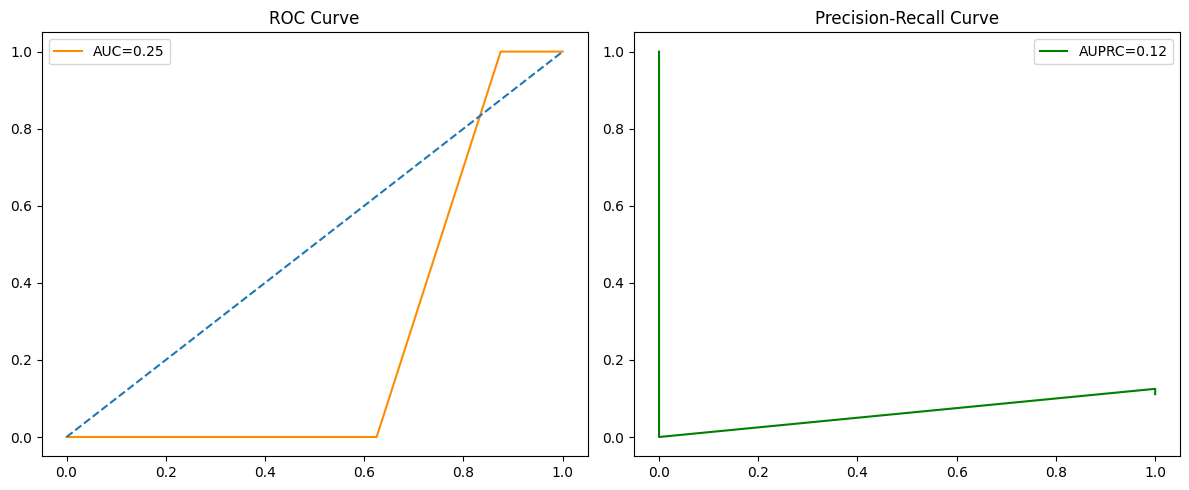


Top 10 Features:
  f260: Notes Embedding (Index 259) - 13.14
  f274: Notes Embedding (Index 273) - 5.65
  f865: Notes Embedding (Index 864) - 4.97
  f704: Notes Embedding (Index 703) - 3.02
  f74: Notes Embedding (Index 73) - 1.04
  f26: Notes Embedding (Index 25) - 0.86
  f8: Notes Embedding (Index 7) - 0.71
  f0: Age (Tabular) - 0.66
  f150: Notes Embedding (Index 149) - 0.63
  f21: Notes Embedding (Index 20) - 0.55


In [8]:
import pandas as pd
import numpy as np
import xgboost as xgb
import sklearn
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
import matplotlib.pyplot as plt
import ast

# ==========================================
# 1. CONFIGURATION
# ==========================================
ID_COL = 'subject_id'   # Ensure this matches your CSV
LABEL_COL = 'label'     # Ensure this matches your CSV

# Set this to True to train ONLY on patients with Notes/Images (Highly Recommended)
# Set to False to train on all 94k patients (mostly empty embeddings)
USE_SUBSET_ONLY = True 

# --- LOAD YOUR DATAFRAMES HERE ---
# tab_df = pd.read_csv(TAB_CSV)
# notes_df = pd.read_csv(NOTES_CSV)
# images_df = pd.read_csv(IMAGES_CSV)
# ecg_df = pd.read_csv(ECG_CSV)
# echo_df = pd.read_csv(ECHO_CSV)

# ==========================================
# 2. CRITICAL FIX: STANDARDIZE IDs & REMOVE LEAKAGE
# ==========================================
print("Standardizing IDs to strings...")
# Ensure matching types across all dataframes
tab_df[ID_COL] = tab_df[ID_COL].astype(str)
if 'notes_df' in locals(): notes_df[ID_COL] = notes_df[ID_COL].astype(str)
if 'images_df' in locals(): images_df[ID_COL] = images_df[ID_COL].astype(str)
if 'ecg_df' in locals(): ecg_df[ID_COL] = ecg_df[ID_COL].astype(str)
#if 'echo_df' in locals(): echo_df[ID_COL] = echo_df[ID_COL].astype(str)

# REMOVE LEAKAGE COLUMNS
# These are random IDs or raw times that confuse the model
leakage_cols = ['hadm_id', 'stay_id', 'intime', 'outtime', 'admittime', 'dischtime', 'dod']
cols_to_drop = [c for c in leakage_cols if c in tab_df.columns]
if cols_to_drop:
    print(f"Dropping data leakage columns: {cols_to_drop}")
    tab_df = tab_df.drop(columns=cols_to_drop)

# ==========================================
# 3. ROBUST PARSING FUNCTIONS
# ==========================================
def parse_embedding(emb):
    """Robustly converts embedding strings to numpy arrays."""
    if pd.isna(emb) or emb == '': return None
    
    if isinstance(emb, str):
        clean_emb = emb.strip("[]").replace("\n", " ")
        if "," in clean_emb:
            try: return np.fromstring(clean_emb, sep=",")
            except: pass
        try: return np.fromstring(clean_emb, sep=" ")
        except: return None
            
    elif isinstance(emb, (list, np.ndarray)):
        return np.array(emb)
    return None

def get_embedding_or_zeros(subject_id, emb_dict, size):
    """Returns the embedding for a subject or a zero-vector if missing."""
    if size == 0: return np.array([]) 
    
    if subject_id in emb_dict and emb_dict[subject_id] is not None:
        arr = np.array(emb_dict[subject_id]).flatten()
        if len(arr) == size: return arr
        if len(arr) < size: return np.pad(arr, (0, size - len(arr)), 'constant')
        return arr[:size]
    return np.zeros(size)

# ==========================================
# 4. PREPARE EMBEDDINGS FIRST
# ==========================================
print("\nParsing embeddings...")
# (Safe checks to assume DFs might not exist in some runs)
if 'notes_df' in locals(): notes_df['text_embed_parsed'] = notes_df['text_embed'].apply(parse_embedding)
if 'images_df' in locals(): images_df['img_embed_parsed'] = images_df['embeddings'].apply(parse_embedding)
if 'ecg_df' in locals(): ecg_df['emb_efficientnet_b0_parsed'] = ecg_df['emb_efficientnet_b0'].apply(parse_embedding)
#if 'echo_df' in locals(): echo_df['embedding_parsed'] = echo_df['embedding'].apply(parse_embedding)

# Create dictionaries
notes_dict = dict(zip(notes_df[ID_COL], notes_df['text_embed_parsed'])) if 'notes_df' in locals() else {}
images_dict = dict(zip(images_df[ID_COL], images_df['img_embed_parsed'])) if 'images_df' in locals() else {}
ecg_dict = dict(zip(ecg_df[ID_COL], ecg_df['emb_efficientnet_b0_parsed'])) if 'ecg_df' in locals() else {}
#echo_dict = dict(zip(echo_df[ID_COL], echo_df['embedding_parsed'])) if 'echo_df' in locals() else {}

# Get Sizes
def get_size(d):
    for v in d.values():
        if v is not None and len(v) > 0: return len(v)
    return 0

NOTES_SIZE = get_size(notes_dict)
IMAGE_SIZE = get_size(images_dict)
ECG_SIZE = get_size(ecg_dict)
#ECHO_SIZE = get_size(echo_dict)

print(f"Sizes -> Notes: {NOTES_SIZE}, Images: {IMAGE_SIZE}, ECG: {ECG_SIZE}")

# ==========================================
# 5. FILTER TABULAR DATA (The "Golden Subset")
# ==========================================
if USE_SUBSET_ONLY:
    print("\nFiltering for patients with multimodal data...")
    # Find IDs that exist in AT LEAST one embedding dictionary
    valid_ids = set()
    if NOTES_SIZE > 0: valid_ids.update(notes_dict.keys())
    if IMAGE_SIZE > 0: valid_ids.update(images_dict.keys())
    if ECG_SIZE > 0:   valid_ids.update(ecg_dict.keys())
    #if ECHO_SIZE > 0:  valid_ids.update(echo_dict.keys())
    
    initial_len = len(tab_df)
    tab_df = tab_df[tab_df[ID_COL].isin(valid_ids)].copy()
    print(f"Reduced dataset from {initial_len} -> {len(tab_df)} rows (only those with embeddings)")

# ==========================================
# 6. PREPROCESSING TABULAR DATA
# ==========================================
print("Preprocessing tabular columns...")

# A. Convert DateTimes to Numeric
for col in tab_df.columns:
    if tab_df[col].dtype == 'object' and col not in [ID_COL, LABEL_COL]:
        try:
            tab_df[col] = pd.to_datetime(tab_df[col], errors='raise') 
            # Convert to numeric timestamp
            tab_df[col] = tab_df[col].astype('int64') // 10**9
        except (ValueError, TypeError):
            continue

# B. One-Hot Encode Categoricals
cols_to_encode = [c for c in tab_df.columns if tab_df[c].dtype == 'object' and c not in [ID_COL, LABEL_COL]]
if cols_to_encode:
    print(f"  - One-hot encoding: {cols_to_encode}")
    tab_df = pd.get_dummies(tab_df, columns=cols_to_encode, dummy_na=True)

# ==========================================
# 7. CONSTRUCT FEATURE MATRIX X
# ==========================================
print("\nBuilding Feature Matrix X...")

numeric_df = tab_df.select_dtypes(include=[np.number])
tabular_cols = [c for c in numeric_df.columns if c not in [ID_COL, LABEL_COL]]
tabular_features = tab_df[tabular_cols].values

print(f"  - Using {len(tabular_cols)} tabular features.")

X_list = []
for i, subject_id in enumerate(tab_df[ID_COL]):
    feats = [tabular_features[i]]
    if NOTES_SIZE > 0: feats.append(get_embedding_or_zeros(subject_id, notes_dict, NOTES_SIZE))
    if IMAGE_SIZE > 0: feats.append(get_embedding_or_zeros(subject_id, images_dict, IMAGE_SIZE))
    if ECG_SIZE > 0:   feats.append(get_embedding_or_zeros(subject_id, ecg_dict, ECG_SIZE))
    #if ECHO_SIZE > 0:  feats.append(get_embedding_or_zeros(subject_id, echo_dict, ECHO_SIZE))
    X_list.append(np.concatenate(feats))

X = np.vstack(X_list)
y = tab_df[LABEL_COL].values
print(f"X shape: {X.shape}, y shape: {y.shape}")

# ==========================================
# 8. TRAIN XGBOOST
# ==========================================
print("\nTraining Model...")

# Use train_test_split instead of KFold (better for small subsets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Handle Class Imbalance
ratio = (len(y_train) - y_train.sum()) / (y_train.sum() + 1e-6)
print(f"Scale Pos Weight Ratio: {ratio:.2f}")

model = xgb.XGBClassifier(
    max_depth=3,            # Shallow trees to prevent overfitting on small data
    learning_rate=0.05,     # Slow learning rate is safer
    n_estimators=100,
    objective='binary:logistic',
    scale_pos_weight=ratio, 
    eval_metric='auc'
)
model.fit(X_train, y_train)

# ==========================================
# 9. EVALUATION
# ==========================================
preds = model.predict(X_test)
preds_proba = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, preds)
try:
    auroc = roc_auc_score(y_test, preds_proba)
    auprc = average_precision_score(y_test, preds_proba)
except ValueError:
    auroc = 0.5
    auprc = 0.0
    print("Warning: Only one class present in test set. AUC undefined.")

print(f"\nResults:")
print(f"  Accuracy: {acc:.4f}")
print(f"  AUROC:    {auroc:.4f}")
print(f"  AUPRC:    {auprc:.4f}")

# Graphs
if len(np.unique(y_test)) > 1:
    fpr, tpr, _ = roc_curve(y_test, preds_proba)
    precision, recall, _ = precision_recall_curve(y_test, preds_proba)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.plot(fpr, tpr, color='darkorange', label=f'AUC={auroc:.2f}')
    ax1.plot([0, 1], [0, 1], linestyle='--')
    ax1.set_title('ROC Curve')
    ax1.legend()
    ax2.plot(recall, precision, color='green', label=f'AUPRC={auprc:.2f}')
    ax2.set_title('Precision-Recall Curve')
    ax2.legend()
    plt.tight_layout()
    plt.show()

# ==========================================
# 10. FEATURE INTERPRETATION
# ==========================================
print("\nTop 10 Features:")
importance = model.get_booster().get_score(importance_type='gain')
sorted_importance = sorted(importance.items(), key=lambda x: x[1], reverse=True)

for feat_id, score in sorted_importance[:10]:
    idx = int(feat_id.replace('f', ''))
    if idx < len(tabular_cols):
        name = tabular_cols[idx]
        print(f"  {feat_id}: {name} (Tabular) - {score:.2f}")
    else:
        # Determine which modality this embedding belongs to
        emb_idx = idx - len(tabular_cols)
        modality = "Unknown"
        if emb_idx < NOTES_SIZE: modality = "Notes"
        elif emb_idx < (NOTES_SIZE + IMAGE_SIZE): modality = "Image"
        elif emb_idx < (NOTES_SIZE + IMAGE_SIZE + ECG_SIZE): modality = "ECG"
        #else: modality = "Echo"
            
        print(f"  {feat_id}: {modality} Embedding (Index {emb_idx}) - {score:.2f}")


In [ ]:
import sklearn
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,  
    roc_curve,
    precision_recall_curve
)


skf = sklearn.model_selection.StratifiedKFold(n_splits=5)
for train_index, test_index in skf.split(X, y):
    pass

X_train = X[train_index]
X_test = X[test_index]
y_train = y[train_index]
y_test = y[test_index]

clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0,
    max_depth=1, random_state=0).fit(X_train, y_train)

preds = clf.predict(X_test)  # Binary predictions
preds_proba = clf.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, preds)
auroc = roc_auc_score(y_test, preds_proba)
auprc = average_precision_score(y_test, preds_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"AUROC: {auroc:.4f}")
print(f"AUPRC: {auprc:.4f}")

fpr, tpr, roc_thresholds = roc_curve(y_test, preds_proba)
precision, recall, pr_thresholds = precision_recall_curve(y_test, preds_proba)

import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# ROC Curve
ax1.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUROC = {auroc:.4f}')
ax1.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve')
ax1.legend(loc="lower right")
ax1.grid(alpha=0.3)

# Precision-Recall Curve
ax2.plot(recall, precision, color='green', lw=2, label=f'AUPRC = {auprc:.4f}')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve')
ax2.legend(loc="lower left")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd

class CustomTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, column_name):
        self.column_name = column_name
    def fit(self, X, y=None):
        return self  # The fit method typically does nothing for transformers
    def transform(self, X):
        # Your transformation logic goes here
        X_transformed = X.copy()  # Copy the input DataFrame to avoid modifying the original
        X_transformed[self.column_name] = X_transformed[self.column_name].apply(lambda x: x * 2)  # Example transformation
        return X_transformed

data = {'feature_1': [1, 2, 3, 4],
        'feature_2': [5, 6, 7, 8]}
df = pd.DataFrame(data)

custom_transformer = CustomTransformer(column_name='feature_1')
df_transformed = custom_transformer.fit_transform(df)
print(df_transformed)
